# Mixed Freeze Audit — S2
Pregunta: ¿excluir estrategias mixtas altera el conjunto de resultados? Mismo juego de dos prestamistas: u_i=a_i(theta+alpha*a_j-c). Enumeramos 81 soportes. Los casos degenerados se rechazan; no afirmamos listar un continuo de equilibrios.

In [1]:
import csv, json
from pathlib import Path
for row in csv.DictReader(Path('results/equilibria.csv').open()): print(row)
print(json.loads(Path('results/summary.json').read_text()))

{'p00': '0.0', 'p01': '0.0', 'p10': '0.0', 'p11': '0.0', 'is_pure': '1', 'regret': '0.0', 'lending_rate': '0.0', 'lender_payoff': '0.0', 'freeze_given_good': '1.0'}
{'p00': '0.0', 'p01': '0.1838235294117646', 'p10': '0.0', 'p11': '0.1838235294117646', 'is_pure': '0', 'regret': '0.0', 'lending_rate': '0.0919117647058823', 'lender_payoff': '0.0', 'freeze_given_good': '0.7275086505190314'}
{'p00': '0.0', 'p01': '1.0', 'p10': '0.0', 'p11': '1.0', 'is_pure': '1', 'regret': '0.0', 'lending_rate': '0.5', 'lender_payoff': '0.4440000000000002', 'freeze_given_good': '0.03999999999999998'}
{'p00': '0.8161764705882353', 'p01': '1.0', 'p10': '0.8161764705882353', 'p11': '1.0', 'is_pure': '0', 'regret': '0.0', 'lending_rate': '0.9080882352941176', 'lender_payoff': '0.6529411764705884', 'freeze_given_good': '0.0013516435986159164'}
{'p00': '1.0', 'p01': '1.0', 'p10': '1.0', 'p11': '1.0', 'is_pure': '1', 'regret': '0.0', 'lending_rate': '1.0', 'lender_payoff': '0.8000000000000002', 'freeze_given_good'

Hipótesis principal: aparecen al menos dos equilibrios adicionales. Contraste negativo: no se presupone que los límites extremos de congelación aumenten. No hay datos empíricos ni probabilidades de selección estimadas.

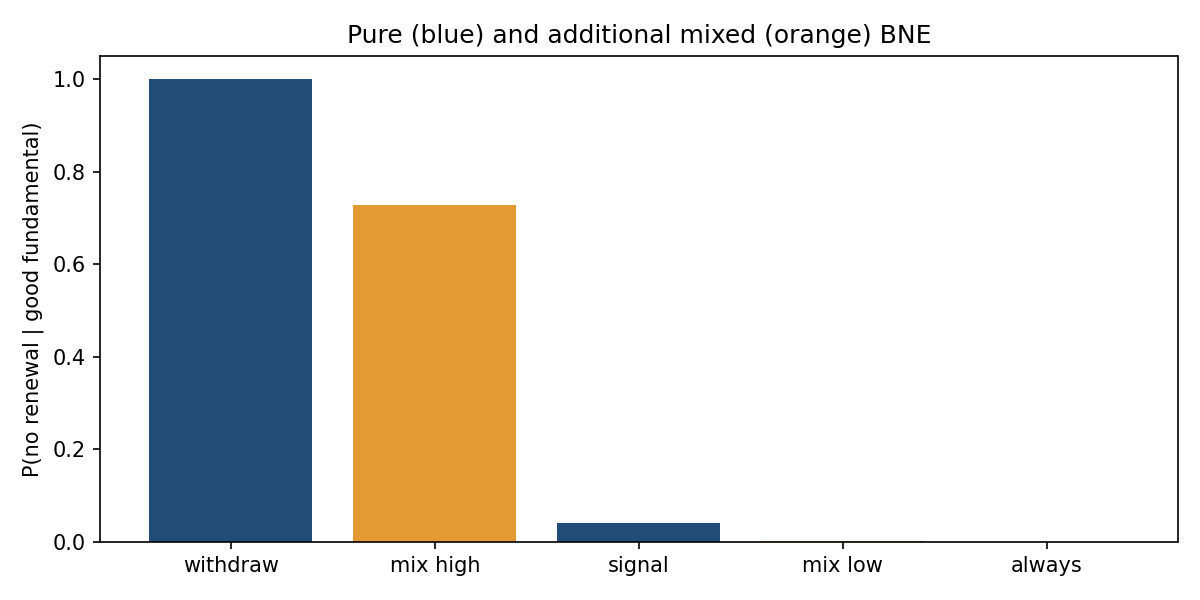

In [2]:
from IPython.display import Image, display
display(Image(filename='results/comparison.png'))

In [3]:
print(Path('results/coverage.txt').read_text())
print(Path('results/negative.csv').read_text())

Name              Stmts   Miss Branch BrPart  Cover   Missing
-------------------------------------------------------------
src/__init__.py       0      0      0      0   100%
src/mixed.py        121      3     54      4    96%   75, 80, 94, 95->56
-------------------------------------------------------------
TOTAL               121      3     54      4    96%

case,status,mixed_count,pure_count
zero_alpha,isolated,1,1
indifference,degenerate_rejected,-1,16



## Desarrollo semanal: mecanismo, sensibilidad y controles

Las celdas nuevas recalculan experimentos específicos. Las salidas históricas anteriores se conservan como evidencia separada y no sustituyen esta ejecución.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


### Condiciones de complementariedad
Para cada tipo, x=0 exige ganancia d≤0, x=1 exige d≥0 y 0<x<1 exige indiferencia d=0. El solver enumera 3⁴ patrones de soporte y valida regret. La enumeración de puros visita sólo 2⁴ patrones y puede perder resultados intermedios.

In [5]:
from src.mixed import Game,solve,rational_oracle,mixed_regret,pure_baseline,outcomes,DegenerateGameError
new_points=solve(Game())
new_oracle=rational_oracle(Game())
assert len(new_points)==len(new_oracle)
assert max(min(np.max(abs(p-np.array(q,float))) for q in new_oracle) for p in new_points)<1e-9
outcome_table=pd.DataFrame([dict(index=i,pure=bool(np.all((x==0)|(x==1))),regret=mixed_regret(Game(),x),**outcomes(Game(),x)) for i,x in enumerate(new_points)])
display(outcome_table.round(6))

,index,pure,regret,lending_rate,lender_payoff,freeze_given_good
0,0,True,0.0,0.000000,0.000000,1.000000
1,1,False,0.0,0.091912,0.000000,0.727509
2,2,True,0.0,0.500000,0.444000,0.040000
3,3,False,0.0,0.908088,0.652941,0.001352
4,4,True,0.0,1.000000,0.800000,0.000000


### Sensibilidad del conjunto, no de un punto seleccionado
Se perturba el costo y se conserva todo el conjunto de equilibrios aislados. En juegos degenerados se registra rechazo explícito. Los rangos de resultados no se interpretan como cuantiles de una distribución de selección.

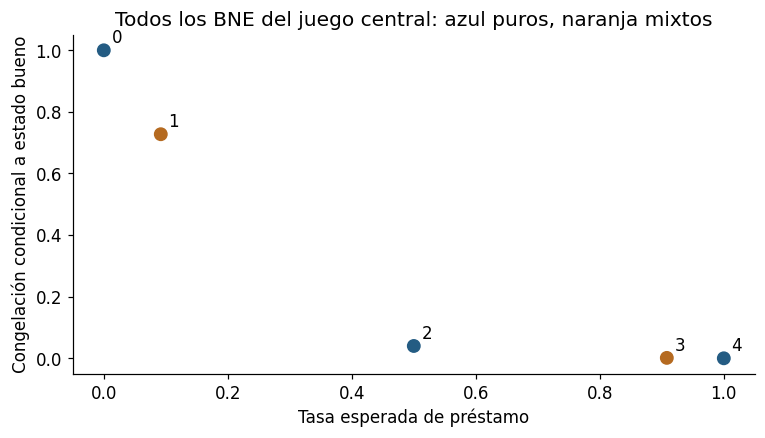

,cost,status,count,pure_count,lending_low,lending_high
0,0.7,isolated,3.0,2,0.5,1.0
1,0.8,degenerate_rejected,NaN,3,NaN,NaN
2,0.9,isolated,5.0,3,0.0,1.0
3,1.0,degenerate_rejected,NaN,3,NaN,NaN
4,1.1,isolated,3.0,2,0.0,0.5


In [6]:
mixed_rows=[]
for cost in [.7,.8,.9,1.,1.1]:
    g=Game(cost=cost)
    try:
        points=solve(g);stats=[outcomes(g,x) for x in points]
        mixed_rows.append(dict(cost=cost,status='isolated',count=len(points),pure_count=len(pure_baseline(g)),
            lending_low=min(s['lending_rate'] for s in stats),lending_high=max(s['lending_rate'] for s in stats)))
    except DegenerateGameError:
        mixed_rows.append(dict(cost=cost,status='degenerate_rejected',count=np.nan,pure_count=len(pure_baseline(g)),lending_low=np.nan,lending_high=np.nan))
display(pd.DataFrame(mixed_rows))
fig,ax=plt.subplots(figsize=(8,4))
ax.scatter(outcome_table.lending_rate,outcome_table.freeze_given_good,c=outcome_table.pure.map({True:'#245C83',False:'#B56A20'}),s=65)
for row in outcome_table.itertuples():ax.annotate(str(row.index),(row.lending_rate,row.freeze_given_good),xytext=(5,5),textcoords='offset points')
ax.set(xlabel='Tasa esperada de préstamo',ylabel='Congelación condicional a estado bueno',title='Todos los BNE del juego central: azul puros, naranja mixtos')
plt.show()

### Control negativo de degeneración
Un continuo no puede certificarse devolviendo una lista finita. El rechazo se trata como limitación del método y se conecta con la representación poliédrica del proyecto siguiente.

In [7]:
try:
    solve(Game(accuracy=.5,cost=.9,complementarity=.8))
except DegenerateGameError as error:
    print('Rechazo esperado:',error)
else:raise AssertionError('El caso de familia debe rechazarse como lista finita')
assert outcome_table.regret.max()<1e-9

Rechazo esperado: Feasible singular support (0, 1, 0, 2); no finite-list certificate
